<img src="./viu_logo.png" width="200">

# 01MIAR - Actividad Whitepapers
Autor: Andrés Felipe Dorado Dorado

# Motivación
<img src="./article_motivation.png" width="750">
<br/>
<small><b>Figura 1.</b> Robots móviles autónomos en almacenes y entornos industriales.</small>
<br/>
<small><i>Fuente: Imagen generada con OpenAI, ChatGPT Image Generation (2026), inspirada conceptualmente en Aggul (2026).</i></small>

Como ingeniero electrónico, especialista en telecomunicaciones y magíster en ciencias de la computación, siento una atracción innata por la robótica y el control de dispositivos autónomos. Cosas que antaño pertenecían únicamente al campo de la ciencia ficción, hoy en día forman parte de manera parcial o absoluta, de nuestro entorno. Por ejemplo, el uso de robots móviles se ha incrementado en fábricas, almacenes (warehouses), laboratorios y entornos logísticos, lo cual supone grandes retos debido a la cantidad de dispositivos, la rapidez de sus operaciones y la necesidad de mantener comunicaciones inalámbricas. Pedimos algo en Amazon y es casi seguro que un robot participa en algún punto de la cadena de procesos.

La posibilidad de delegar la resolución de problemas a nivel de frontera (edge computing) permite optimizar los procesos, reducir los tiempos de respuesta y mejorar la eficiencia.

Desde una perspectiva más técnica, en entornos tan dinámicos es importante procesar enormes cantidades de telemetría procedente de los sensores y sistemas que integran estos dispositivos, como LiDAR, nivel de carga de la batería, jitter, pérdida de paquetes, registros de eventos (logs), entre otros. Cuando estos dispositivos trabajan en enjambres, cualquier retardo o avería puede desencadenar una falla en cascada que afecte al funcionamiento de todo el sistema.

Por ello, se requieren sistemas basados en inteligencia artificial que permitan detectar posibles fallos en estos dispositivos e incluso intentar predecirlos, con el fin de reaccionar de manera anticipada.

# Articulo

## Palabras claves
Para comenzar y contextualizar el tema, conviene definir algunos conceptos clave:

- **ROS (Robot Operating System):** Conjunto de bibliotecas, herramientas y convenciones que facilitan el desarrollo de software para el control de sistemas robóticos (Open Robotics, s. f.).
- **LiDAR (Light Detection and Ranging):** Tecnología de detección remota que utiliza rayos láser para medir distancias con precisión y detectar objetos del entorno en tiempo real (IBM, s. f.).
- **Edge Computing (computación en el borde):** Modelo de computación distribuida que permite acercar el procesamiento de datos y la ejecución de aplicaciones a las fuentes donde se generan, reduciendo la latencia y mejorando los tiempos de respuesta (IBM, 2026).
- **Robotic IoT (Internet de las Cosas aplicado a la robótica):** Integración de tecnologías IoT en sistemas robóticos para mejorar su conectividad, eficiencia y autonomía (Krejčí et al., 2025).

## Definición del problema
El problema que plantean los autores del artículo es la dificultad de obtener un conjunto completo de datos que contemple múltiples escenarios, debido a los elevados costos, el tiempo requerido y los posibles riesgos asociados a su recopilación. Por ello, el artículo presenta un dataset de referencia (*benchmark*), calibrado a partir de pruebas piloto reales, para la detección de anomalías en robots móviles.

## Estructura y recursos en el dataset
El dataset es de acceso abierto y se encuentra disponible junto con los recursos necesarios para su análisis y validación:

- **Benchmark multiescenario:** Generado mediante reglas de simulación físicamente restringidas, que contempla 10 escenarios: uno de funcionamiento normal y nueve con anomalías.
- **Conjunto de datos:** Contiene 120.000 registros tabulados y 38 columnas.
- **Recursos complementarios:** Incluye registros de eventos (*logs*), herramientas de procesamiento (*parsers*), ingeniería de características y scripts de validación, así como un plan por etapas para facilitar su reproducción en entornos reales.

<img src="./dataset_structure.png" width="500">
<br/>
<small><b>Figura 2.</b> Estructura del dataset generado en Aggul (2026).</small>
<br/>
<small><i>Fuente: Aggul, B. (2026).</i></small>

- **Capa de metadatos (*metadata*):** Define los dispositivos, escenarios, sensores, diccionarios de datos y demás información necesaria para contextualizar el dataset.
- **Capa de datos físicos sin procesar:** Contiene los registros originales obtenidos mediante ROS y Jetson Nano.
- **Capa de datos calibrados:** Contiene el dataset generado y calibrado. El archivo principal de interés es `merged_dataset_pilot_real_calibrated_with_jetson.csv`.
- **Directorios auxiliares:** Incluyen documentación complementaria y otros recursos de apoyo relacionados con el dataset.

### Escenarios

Los diez escenarios considerados para la generación del dataset se detallan en la Tabla 1, la cual presenta una versión resumida de la tabla original de Aggul (2026).

<table style="border-collapse: collapse; width: 100%; max-width:500px; text-align: left;">
  <colgroup>
    <col style="width: 70%;">
    <col style="width: 30%;">
  </colgroup>
  <thead>
    <tr>
      <th style="padding: 8px;">Escenario</th>
      <th style="padding: 8px;">Gravedad</th>
    </tr>
  </thead>
  <tbody>
    <tr style="background-color: rgba(0, 180, 0, 0.1);">
      <td>normal_navigation</td><td>0.00</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>obstacle_near</td><td>0.45</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>network_delay</td><td>0.55</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>packet_loss</td><td>0.60</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>cpu_stress</td><td>0.65</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>lidar_noise</td><td>0.50</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>multi_robot_interference</td><td>0.58</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>emergency_stop</td><td>0.90</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>low_battery</td><td>0.70</td>
    </tr>
    <tr style="background-color: rgba(255, 0, 0, 0.1);">
      <td>wheel_slip</td><td>0.75</td>
    </tr>
  </tbody>
</table>
<small><b>Tabla 1.</b> Los 10 robot IoT escenarios para el dataset generado en Aggul (2026).</small>

### Metodos para generacion del Dataset 
En la Figura 3 se muestra el flujo de trabajo (*workflow*) utilizado para generar el dataset final de 120.000 registros.

Asimismo, el artículo detalla los criterios considerados para obtener cada una de las mediciones. Aunque se trata de datos sintéticos calibrados a partir de pruebas piloto en un entorno real, su generación se fundamenta en criterios físicos y matemáticos rigurosos.

Esta información se encuentra documentada en los archivos de metadatos (*metadata*), que se presentarán más adelante.

<img src="./method_workflow.png" width="500">
<br/>
<small><b>Figura 3.</b> Flujo de trabajo para la construccions del dataset generado en Aggul (2026).</small>
<br/>
<small><i>Fuente: Aggul, B. (2026).</i></small>

Existe una gran variedad de mediciones, tanto obtenidas como generadas, tal como se muestra en la Tabla 2. Los autores validaron el dataset resultante mediante diversos criterios de calidad de los datos y del modelado.

<table style="width: 100%; max-width: 750px; table-layout: fixed; border-collapse: collapse; text-align: left;">
  <colgroup>
    <col style="width: 30%;">
    <col style="width: 50%;">
    <col style="width: 20%;">
  </colgroup>
  <thead>
    <tr>
      <th style="padding: 8px;">Categoría de variables</th>
      <th style="padding: 8px;">Nombres de columnas</th>
      <th style="padding: 8px;">Unidades físicas</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 8px;">Cinemática y estado del robot</td>
      <td style="padding: 8px; overflow-wrap: anywhere;">
        <code>cmd_linear_velocity_mps</code>,
        <code>odom_linear_velocity_mps</code>,
        <code>odom_x_m</code>,
        <code>odom_y_m</code>,
        <code>yaw_rad</code>,
        <code>battery_voltage_v</code>,
        <code>cmd_odom_slip_ratio</code>,
        <code>emergency_stop_event</code>
      </td>
      <td style="padding: 8px;">m/s, rad/s, m, V, ratio</td>
    </tr>
    <tr>
      <td style="padding: 8px;">Características LiDAR</td>
      <td style="padding: 8px; overflow-wrap: anywhere;">
        <code>min_lidar_distance_m</code>,
        <code>mean_lidar_distance_m</code>,
        <code>lidar_distance_std_m</code>,
        <code>obstacle_density</code>,
        <code>lidar_outlier_rate</code>
      </td>
      <td style="padding: 8px;">m, ratio, %</td>
    </tr>
    <tr>
      <td style="padding: 8px;">Métricas de procesamiento Edge</td>
      <td style="padding: 8px; overflow-wrap: anywhere;">
        <code>cpu_usage_percent</code>,
        <code>ram_usage_percent</code>,
        <code>gpu_usage_percent</code>,
        <code>device_temperature_c</code>,
        <code>edge_processing_time_ms</code>
      </td>
      <td style="padding: 8px;">%, °C, ms</td>
    </tr>
    <tr>
      <td style="padding: 8px;">Rendimiento de red</td>
      <td style="padding: 8px; overflow-wrap: anywhere;">
        <code>network_latency_ms</code>,
        <code>jitter_ms</code>,
        <code>packet_loss_percent</code>
      </td>
      <td style="padding: 8px;">ms, %</td>
    </tr>
    <tr>
      <td style="padding: 8px;">Etiquetas del benchmark</td>
      <td style="padding: 8px; overflow-wrap: anywhere;">
        <code>run_id</code>,
        <code>scenario_id</code>,
        <code>scenario_name</code>,
        <code>anomaly_label</code>,
        <code>anomaly_severity</code>
      </td>
      <td style="padding: 8px;">Alfanumérico, indicador 0/1, fracción de gravedad</td>
    </tr>
  </tbody>
</table>
<small><b>Tabla 2.</b> Los 10 robot IoT escenarios para el dataset generado en Aggul (2026).</small>

En el capítulo 5 se explica detalladamente el proceso de calibración de los datos reales y sintéticos, así como la aplicación de técnicas de *Machine Learning*, utilizando el algoritmo Random Forest de Scikit-learn. Los resultados obtenidos muestran un desempeño destacado en la clasificación de anomalías, tal como se observa en la matriz de confusión del modelo entrenado.

<img src="./confussion_matrix.png" width="400">
<br/>
<small><b>Figura 3.</b> Multi-clase Random Forest matriz de confusion en Aggul (2026).</small>
<br/>
<small><i>Fuente: Aggul, B. (2026).</i></small>

Es importante destacar las limitaciones señaladas por los autores en el capítulo 7, ya que deben tenerse en cuenta al reproducir, utilizar o ampliar esta investigación. Las principales limitaciones son las siguientes:

- **Benchmark parcialmente sintético:** Las secuencias de los diez escenarios se generaron mediante reglas específicas para cada uno de ellos.
- **Ausencia de un registro maestro sincronizado:** Los datos de los diferentes dispositivos se almacenaron en archivos independientes, sin una sincronización común.
- **Recopilación independiente de datos Edge:** Las métricas de rendimiento se recopilaron únicamente durante pruebas piloto de navegación normal, sin registrarse simultáneamente en todos los escenarios de anomalía.
- **Entornos interiores simplificados:** Las pruebas se realizaron en espacios interiores con obstáculos estáticos, lo que limita la representación de entornos dinámicos reales.

Lo anterior se establece como un resumen del articulo. A continuacion presentare un pequeño desarrollo en python haciendo uso del dataset generado en la investigacion de Aggul (2026).


# Ejemplo de uso
A continuacion, se hace una pequeña implementacion haciendo uso del dataset generado por Aggul(2026), el objetivo es recrear una péqueña parte de lo implementado y obtener un pequeño clasificador de anomalias, usando el mismo proceso que ellos implementaron basado en Random Forest de Sckit-learn.

Teniendo en cuenta que son 38 variables consideradas en el articulo, se extrae un subgrupo para este pequeño analisis, lo cual incluso es intersante con el fin de evaluar si con menos señales es posible obtener valores de precision similares.

<table style="width: 100%; max-width: 750px; border-collapse: collapse; text-align: left;">
  <thead>
    <tr>
      <th style="padding: 8px;">Variable seleccionada</th>
      <th style="padding: 8px;">Justificación</th>
      <th style="padding: 8px;">Categoría</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>min_lidar_distance_m</code></td>
      <td>Detectar obstáculos próximos al robot.</td>
      <td>Características LiDAR</td>
    </tr>
    <tr>
      <td><code>lidar_outlier_rate</code></td>
      <td>Identificar lecturas anómalas del sensor LiDAR.</td>
      <td>Características LiDAR</td>
    </tr>
    <tr>
      <td><code>battery_voltage_v</code></td>
      <td>Identificar posibles problemas de batería.</td>
      <td>Cinemática y estado del robot</td>
    </tr>
    <tr>
      <td><code>cmd_odom_slip_ratio</code></td>
      <td>Detectar diferencias entre el movimiento ordenado y el observado.</td>
      <td>Cinemática y estado del robot</td>
    </tr>
    <tr>
      <td><code>cpu_usage_percent</code></td>
      <td>Identificar condiciones de sobrecarga del procesador.</td>
      <td>Procesamiento Edge</td>
    </tr>
    <tr>
      <td><code>network_latency_ms</code></td>
      <td>Analizar retrasos en las comunicaciones.</td>
      <td>Rendimiento de red</td>
    </tr>
    <tr>
      <td><code>packet_loss_percent</code></td>
      <td>Detectar pérdidas de paquetes durante la comunicación.</td>
      <td>Rendimiento de red</td>
    </tr>
  </tbody>
</table>
<small><b>Tabla 3.</b> Subgrupo de variables seleccionadas al azar.</small>

Se cargara el dataset [merged_dataset_pilot_real_calibrated_with_jetson.csv](./merged_dataset_pilot_real_calibrated_with_jetson%20(2).csv)

In [57]:
# Instalar librerias
# %pip install pandas seaborn matplotlib scikit-learn

# Importar Librerias
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
from sklearn.ensemble import RandomForestClassifier
# https://scikit-learn.org/stable/api/sklearn.metrics.html
from sklearn.metrics import confusion_matrix, accuracy_score

In [58]:
# Cargar y explorar datos
df = pd.read_csv('merged_dataset_pilot_real_calibrated_with_jetson.csv')
print(f'*** Dimensiones: {df.shape}')
display(df.info())

print('*** Primeras filas del dataset:')
display(df.sample(5))

print('*** Información del dataset:')
display(df.describe())

print('*** Valores nulos por columna:', df.isnull().sum(), sep='\n')

*** Dimensiones: (120000, 38)
<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 38 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 120000 non-null  str    
 1   run_id                    120000 non-null  str    
 2   scenario_id               120000 non-null  str    
 3   scenario_name             120000 non-null  str    
 4   robot_id                  120000 non-null  str    
 5   device_id                 120000 non-null  str    
 6   cmd_linear_velocity_mps   120000 non-null  float64
 7   cmd_angular_velocity_rps  120000 non-null  float64
 8   odom_linear_velocity_mps  120000 non-null  float64
 9   odom_x_m                  120000 non-null  float64
 10  odom_y_m                  120000 non-null  float64
 11  yaw_rad                   120000 non-null  float64
 12  battery_voltage_v         120000 non-null  float64
 13  cmd_odom_slip_ratio      

C:\Users\andre\AppData\Local\Temp\ipykernel_34184\1923879994.py:2: DtypeWarning: Columns (37: calibration_reference) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('merged_dataset_pilot_real_calibrated_with_jetson.csv')


None

*** Primeras filas del dataset:


,timestamp,run_id,scenario_id,scenario_name,robot_id,device_id,cmd_linear_velocity_mps,cmd_angular_velocity_rps,odom_linear_velocity_mps,odom_x_m,...,network_latency_ms,packet_loss_percent,jitter_ms,dropped_message_count,synchronization_drift_ms,anomaly_label,anomaly_severity,data_origin,calibration_status,calibration_reference
9252,2026-05-01T09:58:06Z,RUN_0008,S01,normal_navigation,tb3_burger_02,tb3_burger_02,0.1470,-0.2203,0.1325,4.2209,...,40.10,0.451,0.00,0,2.62,0,0.027,synthetic_pilot_real_calibrated,normal_navigation_lidar_distribution_aligned_t...,TurtleBot3 LD08 LiDAR pilot + Jetson Nano edge...
42189,2026-05-01T13:13:34.500000Z,RUN_0036,S04,packet_loss,tb3_burger_01,tb3_burger_01,0.0686,0.3300,0.0776,3.3713,...,100.32,8.253,19.17,3,8.53,1,0.618,synthetic_original,not_calibrated_no_real_reference_for_this_scen...,NaN
9664,2026-05-01T10:03:32Z,RUN_0009,S01,normal_navigation,tb3_burger_01,tb3_burger_01,0.1089,-0.0813,0.0921,0.6955,...,14.33,0.346,4.80,0,3.65,0,0.006,synthetic_pilot_real_calibrated,normal_navigation_lidar_distribution_aligned_t...,TurtleBot3 LD08 LiDAR pilot + Jetson Nano edge...
119285,2026-05-01T20:44:02.500000Z,RUN_0100,S10,wheel_slip,tb3_burger_01,tb3_burger_01,0.1218,-0.0545,0.0883,0.6197,...,28.82,0.036,4.96,0,2.93,1,0.783,synthetic_original,not_calibrated_no_real_reference_for_this_scen...,NaN
116564,2026-05-01T20:27:22Z,RUN_0098,S10,wheel_slip,tb3_burger_01,tb3_burger_01,0.0988,0.0558,0.0414,0.9705,...,16.56,0.350,5.50,0,4.91,1,0.737,synthetic_original,not_calibrated_no_real_reference_for_this_scen...,NaN


*** Información del dataset:


,cmd_linear_velocity_mps,cmd_angular_velocity_rps,odom_linear_velocity_mps,odom_x_m,odom_y_m,yaw_rad,battery_voltage_v,cmd_odom_slip_ratio,emergency_stop_event,min_lidar_distance_m,...,gpu_usage_percent,device_temperature_c,edge_processing_time_ms,network_latency_ms,packet_loss_percent,jitter_ms,dropped_message_count,synchronization_drift_ms,anomaly_label,anomaly_severity
count,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,...,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000
mean,0.108310,0.012374,0.100019,4.253738,2.020196,0.127564,11.36969,0.077462,0.016500,0.889060,...,16.315652,52.002206,51.464220,38.111444,1.361075,9.443875,0.306917,6.427084,0.900000,0.569459
std,0.032007,0.210917,0.036663,2.981259,2.916377,1.502953,0.30105,0.092600,0.127389,0.393867,...,9.976939,8.241438,26.695262,29.400151,2.687249,11.302387,0.876931,8.211852,0.300001,0.224983
min,0.000000,-0.600100,0.000000,-5.605800,-8.538900,-3.141200,10.14800,0.000000,0.000000,0.050000,...,0.000000,28.000000,6.290000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.085300,-0.169500,0.076000,1.659800,0.381500,-0.878525,11.37300,0.035400,0.000000,0.594000,...,9.347500,47.330000,36.170000,21.530000,0.222000,3.200000,0.000000,2.830000,1.000000,0.499000
50%,0.111100,0.017100,0.101600,3.915950,1.347350,0.217200,11.45000,0.053500,0.000000,0.930000,...,16.780000,50.068200,43.470000,27.730000,0.423000,5.020000,0.000000,4.270000,1.000000,0.593000
75%,0.133900,0.192000,0.129000,6.225100,3.548725,1.172900,11.52500,0.074200,0.000000,1.174000,...,23.370000,54.180000,57.820000,40.070000,0.708000,9.990000,0.000000,5.910000,1.000000,0.701000
max,0.190100,0.563100,0.206700,13.676600,12.877300,3.141500,11.72800,0.720000,1.000000,2.522000,...,57.650000,91.000000,245.690000,246.770000,20.777000,94.020000,10.000000,64.440000,1.000000,1.000000


*** Valores nulos por columna:
timestamp                        0
run_id                           0
scenario_id                      0
scenario_name                    0
robot_id                         0
device_id                        0
cmd_linear_velocity_mps          0
cmd_angular_velocity_rps         0
odom_linear_velocity_mps         0
odom_x_m                         0
odom_y_m                         0
yaw_rad                          0
battery_voltage_v                0
cmd_odom_slip_ratio              0
emergency_stop_event             0
min_lidar_distance_m             0
mean_lidar_distance_m            0
lidar_distance_std_m             0
obstacle_density                 0
lidar_outlier_rate               0
ros_topic_rate_hz                0
edge_device_id                   0
cpu_usage_percent                0
ram_usage_percent                0
gpu_usage_percent                0
device_temperature_c             0
edge_processing_time_ms          0
network_device_id       

El dataset contiene, efectivamente, 120.000 registros y 38 columnas, de las cuales 27 corresponden a variables numéricas.

Se observa que 37 columnas no presentan valores nulos, mientras que `calibration_reference` contiene 108.000 valores ausentes. Esto tiene sentido, ya que dicha columna contiene información relacionada con la calibración del dataset.

La variable `anomaly_label`, que se utilizará como variable de salida del clasificador, presenta una media de 0,9, lo que indica que el 90% de los registros corresponde a anomalías y el 10% a funcionamiento normal.


In [59]:
# Preparacion de datos (Extraccion de subdataset)
display(df['scenario_name'].unique())

display(df['anomaly_label'].value_counts())

# Seleccionar subdataset 
features = [
    'min_lidar_distance_m',
    'lidar_outlier_rate',
    'battery_voltage_v',
    'cmd_odom_slip_ratio',
    'cpu_usage_percent',
    'network_latency_ms',
    'packet_loss_percent',
]
non_features = ['anomaly_label', 'anomaly_severity', 'scenario_name', 'run_id']

display(df[features].describe())

# Obtener el subdataset con las características seleccionadas
df = df[features + non_features]

# Cambiar numeros [0,1] por etiquetas de anomaly_labels
df['status'] = df['anomaly_label'].map({0: 'normal', 1: 'anomaly'})

display(df.sample(5))


<StringArray>
[       'normal_navigation',            'obstacle_near',
            'network_delay',              'packet_loss',
               'cpu_stress',              'lidar_noise',
 'multi_robot_interference',           'emergency_stop',
              'low_battery',               'wheel_slip']
Length: 10, dtype: str

anomaly_label
1    108000
0     12000
Name: count, dtype: int64

,min_lidar_distance_m,lidar_outlier_rate,battery_voltage_v,cmd_odom_slip_ratio,cpu_usage_percent,network_latency_ms,packet_loss_percent
count,120000.000000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000
mean,0.889060,0.065057,11.36969,0.077462,39.410411,38.111444,1.361075
std,0.393867,0.109189,0.30105,0.092600,20.599576,29.400151,2.687249
min,0.050000,0.000000,10.14800,0.000000,0.000000,3.000000,0.000000
25%,0.594000,0.011100,11.37300,0.035400,28.980000,21.530000,0.222000
50%,0.930000,0.017600,11.45000,0.053500,37.490000,27.730000,0.423000
75%,1.174000,0.027300,11.52500,0.074200,46.230000,40.070000,0.708000
max,2.522000,0.434500,11.72800,0.720000,100.000000,246.770000,20.777000


,min_lidar_distance_m,lidar_outlier_rate,battery_voltage_v,cmd_odom_slip_ratio,cpu_usage_percent,network_latency_ms,packet_loss_percent,anomaly_label,anomaly_severity,scenario_name,run_id,status
41806,1.183,0.0126,11.402,0.0405,21.51,43.28,6.394,1,0.572,packet_loss,RUN_0035,anomaly
77996,1.085,0.0150,11.333,0.0477,65.82,52.21,4.223,1,0.591,multi_robot_interference,RUN_0065,anomaly
13661,0.589,0.0325,11.350,0.0403,45.53,20.30,0.481,1,0.428,obstacle_near,RUN_0012,anomaly
74729,0.748,0.0126,11.419,0.0155,37.67,73.53,2.461,1,0.606,multi_robot_interference,RUN_0063,anomaly
98888,0.987,0.0221,10.343,0.0472,19.19,21.52,0.425,1,0.723,low_battery,RUN_0083,anomaly


Con el dataset reducido ahora es posible visualizar un poco sus datos con seaborn y matplotlib.

C:\Users\andre\AppData\Local\Temp\ipykernel_34184\2246590090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


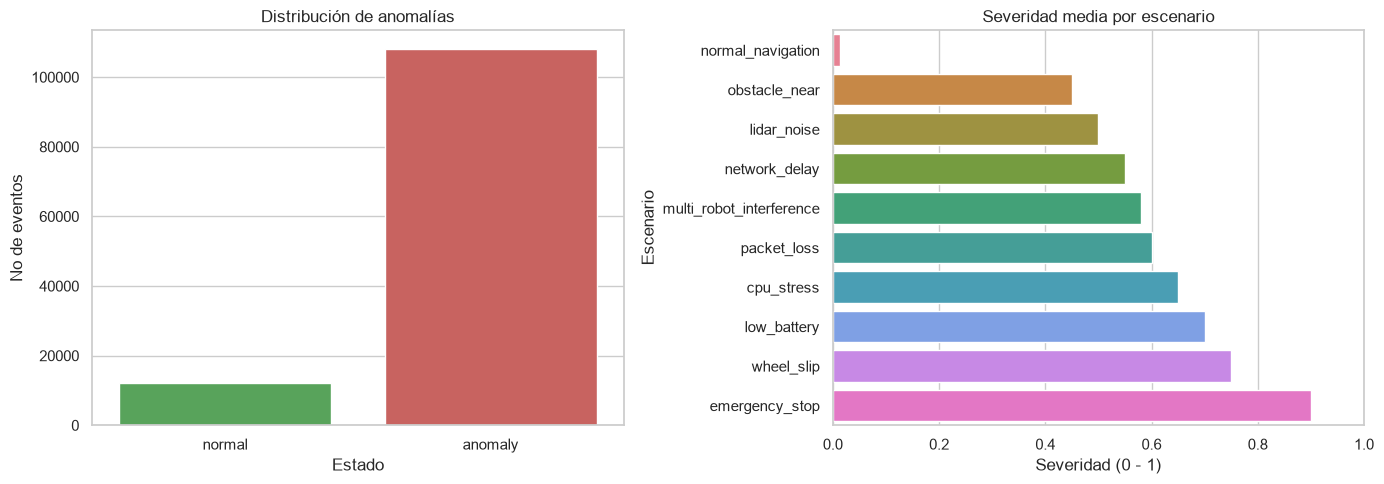

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de anomalías
sns.countplot(
    data=df,
    x='status',
    order=['normal', 'anomaly'],
    palette={'normal': '#4CAF50', 'anomaly': '#D9534F'},
    ax=axes[0],
)
axes[0].set_title('Distribución de anomalías')
axes[0].set_xlabel('Estado')
axes[0].set_ylabel('No de eventos')

# Analisis de severidad de anomalías por escenario
severity = (
    df.groupby('scenario_name', as_index=False)
    ['anomaly_severity']
    .mean()
    .sort_values('anomaly_severity')
)

sns.barplot(
    data=severity,
    x='anomaly_severity',
    y='scenario_name',
    hue='scenario_name',
    ax=axes[1],
)
axes[1].set_title('Severidad media por escenario')
axes[1].set_xlabel('Severidad (0 - 1)')
axes[1].set_ylabel('Escenario')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

# Conclusiones

- La importancia de los datos en entornos reales permiten la realizacion de estudios proximos a la realidad y la posibiliad de extrapolar eventos futuros o inciertos con un margen menor de riesgo, aun asi herramientas de simulacion pueden generar informacion sintetica, que despues de ser procesada, sirven como base para estudios similares.


# 5. Referencias
Aggul, B. (2026). A pilot-real-calibrated indoor robotic IoT benchmark dataset for edge-assisted mobile robot navigation and anomaly detection. Data, 11(7), Article 165. https://doi.org/10.3390/data11070165

Ağgül, B. (2026). A pilot-real-calibrated indoor robotic IoT benchmark dataset for edge-assisted mobile robot navigation and anomaly detection (Version 1.0.0) [Conjunto de datos]. Zenodo. https://doi.org/10.5281/zenodo.20346694

GitHub. (2026). GitHub Copilot [Asistente de programación con inteligencia artificial]. https://github.com/features/copilot

IBM. (s. f.). *What is LiDAR?*. Recuperado el 4 de noviembre de 2026, de https://www.ibm.com/think/topics/lidar

IBM. (2026, 31 de marzo). *What is edge computing?*. Recuperado el 4 de noviembre de 2026, de https://www.ibm.com/think/topics/edge-computing

Krejčí, J., Babiuch, M., Suder, J., & Krys, V. (2025). Internet of robotic things: Current technologies, challenges, applications, and future research topics. *Sensors, 25*(3), Article 765. https://doi.org/10.3390/s25030765

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje de gran tamaño]. https://chatgpt.com/

Open Robotics. (s. f.). *ROS Wiki*. Recuperado el 6 de noviembre de 2026, de https://wiki.ros.org/

# 6. Declaración uso de la IA
Se utilizaron ChatGPT (OpenAI) y Copilot como herramientas de apoyo en las siguientes actividades:

* Investigación y clasificación bibliográfica: Búsqueda exploratoria y comparación de artículos científicos relacionados con inteligencia artificial y Python. Las herramientas contribuyeron a localizar publicaciones, evaluar su relevancia y accesibilidad, y verificar la disponibilidad de datasets.

* Planificación de la actividad: Apoyo en la revisión de las instrucciones académicas y del ejemplo proporcionado por el profesor.

* Formato y estilo: Asistencia mediante autocompletado, corrección ortográfica y revisión del estilo de redacción, así como en el formato de markdown y de las referencias bibliográficas según las normas APA.

* Generacion de assets: La image de la seccion de motivacion fue generada con herramienta de IA, las tablas fueron generadas en html.

* Sugerencia de codigo: En la seccion de implementacion, algunos conceptos fueron sugeridos y/o revisados por IA, no sin antes ser comprobados directamente en las fuentes oficiales de la herramienta.